# Praktikum 2 - Klasifikasi Naive Bayes dengan Data Dummy

**Nama:** Mohammad Al Hafis Hidayatulloh  
**NIM:** 254107023005  
**Mata Kuliah:** RTI235004 - Pembelajaran Mesin  
**Dosen Pengampu:** Usman Nurhasan, S.Kom., M.T.

---

## Langkah 1 - Buat Dataset Dummy (`make_classification`)

Pada praktikum kedua ini saya membangkitkan `30` sampel data sintetis berdimensi 2 dengan 2 kelas menggunakan fungsi `make_classification`, kemudian mengubah nilainya menjadi bilangan bulat positif untuk diuji pada model `MultinomialNB` dan `GaussianNB`.

In [1]:
import numpy as np
from sklearn.datasets import make_classification

np.random.seed(29)
# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X, y = make_classification(
    n_samples=30, n_features=2, n_classes=2,
    n_informative=2, n_redundant=0, n_repeated=0, shuffle=False
)

# Secara default, make_classification menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutkan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print(X)
print(y)

[[ 70  90]
 [149 147]
 [ 19 118]
 [ 16 120]
 [124 120]
 [157  96]
 [138  64]
 [129 124]
 [119 106]
 [152 314]
 [129  47]
 [121  23]
 [ 91 197]
 [150 322]
 [ 94 168]
 [142 260]
 [ 89  87]
 [158  69]
 [112  44]
 [ 95 154]
 [ 22  82]
 [114  63]
 [ 14  18]
 [219  62]
 [164 261]
 [ 72 178]
 [161 250]
 [110  16]
 [123 227]
 [ 20   5]]
[0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


## Langkah 2 (Opsional) - Membuat Data Frame

Menggabungkan matriks fitur `X` dan vektor label `y` ke dalam sebuah DataFrame Pandas dengan kolom `['Fitur 1', 'Fitur 2', 'Label']`.

In [2]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,70,90,0
1,149,147,0
2,19,118,0
3,16,120,0
4,124,120,0


## Langkah 3 (Opsional) - Labeling

Memetakan kode angka pada kolom `Label` menjadi nama kategori yang mudah dibaca (`1: 'Kelas A'`, `0: 'Kelas B'`).

In [3]:
# Definisikan nama label
labels = {
    1: 'Kelas A',
    0: 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru
# dengan label yang mudah untuk dibaca
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
# pada Data Frame df_label
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,70,90,Kelas B
1,149,147,Kelas B
2,19,118,Kelas B
3,16,120,Kelas B
4,124,120,Kelas B


## Langkah 4 - Visualisasi Data

Menampilkan sebaran titik data untuk `Kelas A` dan `Kelas B` pada bidang 2 dimensi (`Fitur 1` vs `Fitur 2`).

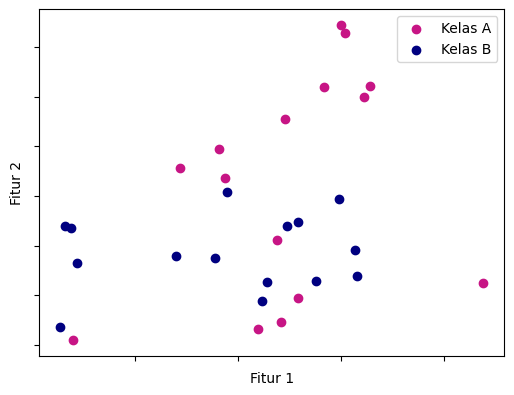

In [4]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby('Label')
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.figure(figsize=(6, 4.5))
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'])
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'])
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

## Langkah 5 - Model Multinomial Naive Bayes

Membagi data dummy menjadi `70%` data latih (`21` sampel) dan `30%` data uji (`9` sampel) dengan `random_state = 30`, lalu melatih dan mengevaluasi model `MultinomialNB`.

In [5]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Hasil akurasi data train: 0.6190476190476191
Hasil akurasi data test: 0.6666666666666666


## Langkah 6 - Model Gaussian Naive Bayes

Menggunakan pembagian `X_train` dan `X_test` yang sama untuk melatih dan mengevaluasi model `GaussianNB`.

In [6]:
from sklearn.naive_bayes import GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.8095238095238095
Hasil akurasi data test (Gaussian): 0.7777777777777778


### Analisis Hasil Praktikum 2

Pada percobaan di atas, `MultinomialNB` menghasilkan akurasi *training* sebesar `0.6190` (`61.90%`) dan akurasi *testing* sebesar `0.6667` (`66.67%`), sedangkan `GaussianNB` menghasilkan akurasi yang jauh lebih baik yaitu `0.8095` (`80.95%`) pada data *training* dan `0.7778` (`77.78%`) pada data *testing*. Secara teoritis, hal ini disebabkan karena data dari `make_classification` dibangkitkan dari klaster berdistribusi normal (Gaussian) di ruang kontinu—meskipun nilainya sudah dibulatkan menjadi bilangan bulat positif, `GaussianNB` mengestimasi rata-rata ($\mu$) dan varians ($\sigma^2$) tiap fitur per kelas sehingga mampu memisahkan kedua kelas dengan lebih tepat dibanding `MultinomialNB` yang hanya melihat perbandingan proporsi frekuensi relatif antara `Fitur 1` dan `Fitur 2`.